# 01 Annealing y otros solvers: Max-Cut de 5 nodos

Mismo QUBO de la sesión 01: referencia exacta, recocido simulado con `neal`, evolución adiabática ideal con QuTiP, bifurcación simulada y Fujitsu Digital Annealer vía DADK.
Referencia: handbook, capítulos AQC y formulación QUBO.

In [ ]:
!pip install -q dwave-neal dimod networkx matplotlib qutip

## 1. Grafo y matriz Q (idéntica a `05-qubo-max-cut.ipynb`)


In [8]:
import networkx as nx
import numpy as np

G = nx.Graph()
G.add_edges_from([(1,2),(1,3),(2,4),(3,4),(3,5),(4,5)])

n = G.number_of_nodes()
nodes = list(G.nodes)

Q = np.zeros((n,n))
for u,v in G.edges:
    i,j = nodes.index(u), nodes.index(v)
    Q[i,i]+=1; Q[j,j]+=1; Q[i,j]-=1; Q[j,i]-=1
Q = -1.0*Q
print(Q)


[[-2.  1.  1. -0. -0.]
 [ 1. -2. -0.  1. -0.]
 [ 1. -0. -3.  1.  1.]
 [-0.  1.  1. -3.  1.]
 [-0. -0.  1.  1. -2.]]


## 2. Referencia exacta (varias soluciones posibles)

In [9]:
import dimod

bqm = dimod.BQM(Q, "BINARY")

exact = dimod.ExactSolver().sample(bqm) # Fuerza bruta

print(exact.truncate(4))

   0  1  2  3  4 energy num_oc.
0  0  1  1  0  0   -5.0       1
1  1  0  0  1  0   -5.0       1
2  0  1  1  0  1   -5.0       1
3  1  0  0  1  1   -5.0       1
['BINARY', 4 rows, 4 samples, 5 variables]


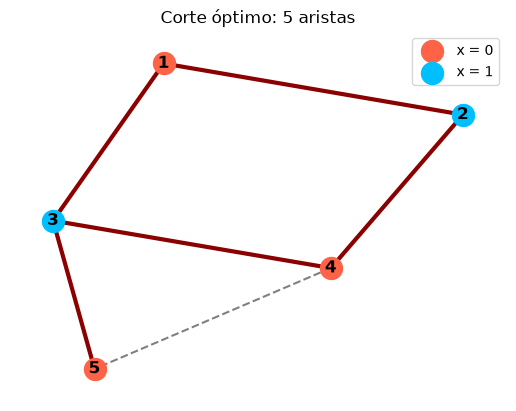

In [11]:
import matplotlib.pyplot as plt

best_sample = exact.first.sample
cut_edges = [(u, v) for u, v in G.edges if best_sample[nodes.index(u)] != best_sample[nodes.index(v)]]
uncut_edges = [(u, v) for u, v in G.edges if best_sample[nodes.index(u)] == best_sample[nodes.index(v)]]
set_0 = [node for i, node in enumerate(nodes) if best_sample[i] == 0]
set_1 = [node for i, node in enumerate(nodes) if best_sample[i] == 1]
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(G, pos, nodelist=set_0, node_color="tomato", node_size=250, label="x = 0")
nx.draw_networkx_nodes(G, pos, nodelist=set_1, node_color="deepskyblue", node_size=250, label="x = 1")
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, edge_color="darkred", width=3)
nx.draw_networkx_edges(G, pos, edgelist=uncut_edges, edge_color="gray", width=1.5, style="dashed")
nx.draw_networkx_labels(G, pos, font_weight="bold")
plt.title(f"Corte óptimo: {len(cut_edges)} aristas")
plt.legend(); plt.axis("off"); plt.show()

## 3. Annealing simulado: efecto de _num_reads_


In [12]:
import neal

for reads in [50, 500]:
    s = neal.SimulatedAnnealingSampler().sample(bqm, num_reads=reads, seed=1)
    print(reads, s.first.energy, s.first.sample)

50 -5.0 {0: np.int8(0), 1: np.int8(1), 2: np.int8(1), 3: np.int8(0), 4: np.int8(0)}
500 -5.0 {0: np.int8(1), 1: np.int8(0), 2: np.int8(0), 3: np.int8(1), 4: np.int8(0)}


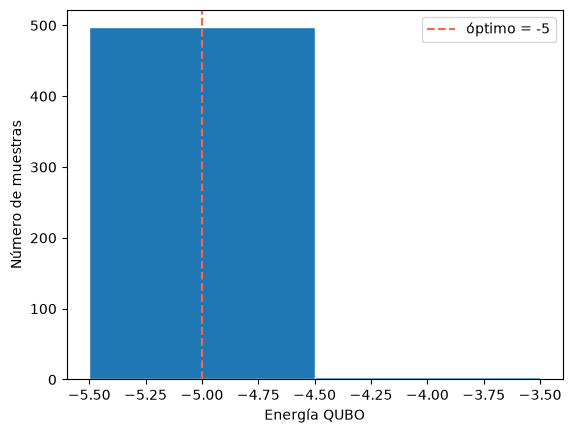

Muestras óptimas: 99.4% (497/500)


In [13]:
reads = 500
samples_sa = neal.SimulatedAnnealingSampler().sample(bqm, num_reads=reads, seed=1)
energies_sa = np.asarray(samples_sa.record.energy)
energy_opt = float(exact.first.energy)
fraction_opt = np.mean(np.isclose(energies_sa, energy_opt))

bins = np.arange(energies_sa.min() - 0.5, energies_sa.max() + 1.5, 1)
plt.hist(energies_sa, bins=bins, edgecolor="white")
plt.axvline(energy_opt, color="tomato", linestyle="--", label=f"óptimo = {energy_opt:g}")
plt.xlabel("Energía QUBO"); plt.ylabel("Número de muestras"); plt.legend(); plt.show()
print(f"Muestras óptimas: {fraction_opt:.1%} ({int(fraction_opt * reads)}/{reads})")

## 4. Quantum Annealing con QuTiP

Para este grafo pequeño podemos integrar la ecuación de Schrödinger y observar una evolución adiabática cerrada. Es una **simulación exacta de estado**, no una QPU ni un modelo del ruido, la disipación o el control de un annealer comercial. Su coste crece exponencialmente, así que aquí solo usamos 5 qubits.

Con $s=t/T$, usamos:

$$
H(s)=(1-s)H_I+sH_P
$$

donde $H_I=-\sum_i X_i$ y, para Max-Cut, $H_P=\frac{1}{2}\sum_{(i,j)\in E}Z_iZ_j-\frac{|E|}{2}I$. El término constante hace que la energía final coincida con el QUBO, no cambia los estados propios.

In [20]:
from qutip import basis, expect, qeye, sesolve, sigmax, sigmaz, tensor

# Preparamos las operaciones
identity = qeye(2)
x_ops, z_ops = [], []
for i in range(n):
    x_factors = [identity] * n
    z_factors = [identity] * n
    x_factors[i] = sigmax()
    z_factors[i] = sigmaz()
    x_ops.append(tensor(x_factors))
    z_ops.append(tensor(z_factors))

Preparamos el problema inicial ($H_{inicial}$) y el problema objetivo ($H_{problema}$).

In [23]:
psi_initial = tensor([(basis(2, 0) + basis(2, 1)).unit() for _ in range(n)])
psi_initial

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]
 [0.1767767]]

In [24]:
H_initial = sum((-op for op in x_ops), 0 * x_ops[0])
H_initial

Quantum object: dims=[[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape=(32, 32), type='oper', dtype=CSR, isherm=True
Qobj data =
[[ 0. -1. -1. ...  0.  0.  0.]
 [-1.  0.  0. ...  0.  0.  0.]
 [-1.  0.  0. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ...  0.  0. -1.]
 [ 0.  0.  0. ...  0.  0. -1.]
 [ 0.  0.  0. ... -1. -1.  0.]]

In [25]:
H_problem = sum(
    (0.5 * z_ops[nodes.index(u)] * z_ops[nodes.index(v)] for u, v in G.edges),
    0 * z_ops[0],
) - 0.5 * G.number_of_edges() * tensor([identity] * n)
H_problem

Quantum object: dims=[[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape=(32, 32), type='oper', dtype=CSR, isherm=True
Qobj data =
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 0. -2.  0. ...  0.  0.  0.]
 [ 0.  0. -3. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ... -3.  0.  0.]
 [ 0.  0.  0. ...  0. -2.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]]

In [26]:
H_anneal = [
    [H_initial, lambda t, **kwargs: 1 - t / kwargs["duration"]],
    [H_problem, lambda t, **kwargs: t / kwargs["duration"]],
]

Y ahora simulamos la mezcla a distintas velocidades...

In [22]:
optimal_indices = {
    sum(int(sample[i]) << (n - 1 - i) for i in range(n))
    for sample, energy in exact.data(fields=["sample", "energy"])
    if np.isclose(energy, energy_opt)
}
anneal_success = []
for duration in [2.0, 10.0, 30.0]:
    times = np.linspace(0, duration, int(10 * duration) + 1)
    result = sesolve(
        H_anneal, psi_initial, times,
        args={"duration": duration},
        options={"store_states": True},
    )
    probabilities = np.abs(result.states[-1].full().ravel()) ** 2
    success = float(probabilities[list(optimal_indices)].sum())
    anneal_success.append(success)
    energy_final = float(np.real(expect(H_problem, result.states[-1])))
    print(f"T = {duration:4.1f}: P(óptimo) = {success:.3f}; <H_P> = {energy_final:.3f}")

T =  2.0: P(óptimo) = 0.354; <H_P> = -3.943
T = 10.0: P(óptimo) = 0.867; <H_P> = -4.859
T = 30.0: P(óptimo) = 0.998; <H_P> = -4.998


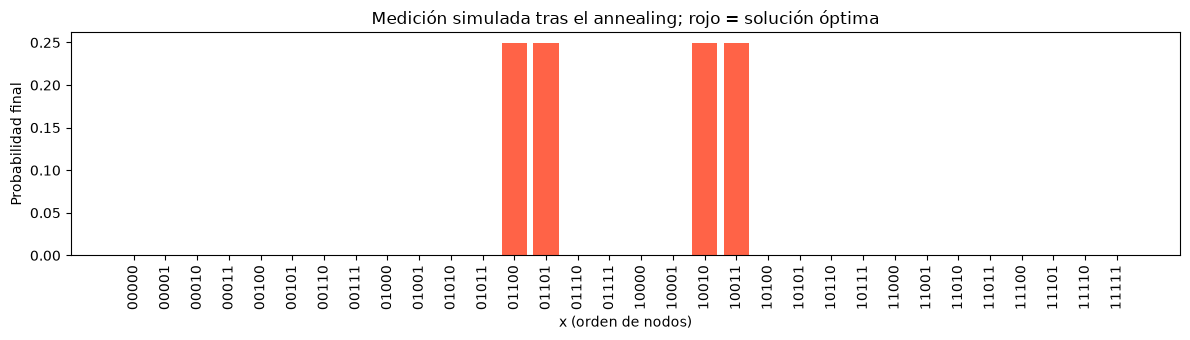

In [19]:
bitstrings = [format(i, f"0{n}b") for i in range(2**n)]
bar_colors = ["tomato" if i in optimal_indices else "steelblue" for i in range(2**n)]
plt.figure(figsize=(12, 3.5))
plt.bar(bitstrings, probabilities, color=bar_colors)
plt.xticks(rotation=90); plt.ylabel("Probabilidad final"); plt.xlabel("x (orden de nodos)")
plt.title("Medición simulada tras el annealing; rojo = solución óptima")
plt.tight_layout(); plt.show()

## 5. Bifurcación simulada

La bifurcación simulada (*simulated bifurcation*, SB) es otra heurística clásica inspirada en la dinámica de osciladores no lineales: simula la trayectoria de variables continuas y lee cada resultado como espines $s_i=\mathrm{sign}(x_i)$. Aquí usamos una versión didáctica de **ballistic SB** con saturación cúbica y un parámetro de bifurcación creciente; no es una simulación cuántica ni una implementación optimizada de hardware.

Para Max-Cut se maximiza $-\sum_{(i,j)\in E}s_is_j$, así que la matriz de acoplamientos es $J=-A$ (con $A$ la adyacencia). Cada trayectoria da una muestra binaria, que evaluamos con el mismo QUBO y comparamos con el óptimo exacto.

In [16]:
adjacency = nx.to_numpy_array(G, nodelist=nodes, dtype=float)

J = -adjacency
rng = np.random.default_rng(7)
num_runs, steps, dt, coupling = 64, 1000, 0.02, 0.1
sb_samples, sb_energies = [], []

for _ in range(num_runs):
    x = rng.normal(0, 0.01, n)
    momentum = rng.normal(0, 0.01, n)
    for step in range(steps):
        p = 2.0 * (step + 1) / steps
        acceleration = (p - 1.0) * x - x**3 + coupling * (J @ x)
        momentum += dt * acceleration
        x += dt * momentum

    spins = np.where(x >= 0, 1, -1)
    bits = ((1 - spins) // 2).astype(int)
    sb_samples.append(bits)
    sb_energies.append(float(bits @ Q @ bits))

sb_energies = np.asarray(sb_energies)
sb_best = float(sb_energies.min())
sb_fraction_opt = float(np.mean(np.isclose(sb_energies, energy_opt)))
best_bits = sb_samples[int(np.argmin(sb_energies))]
print(f"SB mejor energía: {sb_best:.1f} (óptimo exacto: {energy_opt:.1f})")
print(f"Fracción de soluciones óptimas: {sb_fraction_opt:.1%} ({num_runs} trayectorias)")
print("Mejor muestra:", dict(zip(range(n), best_bits)))

SB mejor energía: -5.0 (óptimo exacto: -5.0)
Fracción de soluciones óptimas: 78.1% (64 trayectorias)
Mejor muestra: {0: np.int64(0), 1: np.int64(1), 2: np.int64(1), 3: np.int64(0), 4: np.int64(0)}


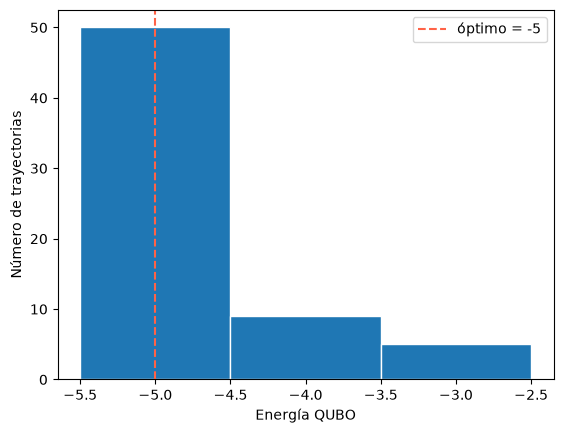

In [17]:
bins = np.arange(sb_energies.min() - 0.5, sb_energies.max() + 1.5, 1)
plt.hist(sb_energies, bins=bins, edgecolor="white")
plt.axvline(energy_opt, color="tomato", linestyle="--", label=f"óptimo = {energy_opt:g}")
plt.xlabel("Energía QUBO"); plt.ylabel("Número de trayectorias"); plt.legend(); plt.show()

En un grafo de cinco nodos ambos métodos son comparables solo como demostración: la simulación con QuTiP resuelve una dinámica cuántica ideal de 32 amplitudes, mientras que SB integra ecuaciones clásicas. No extrapoles estos resultados a una ventaja de rendimiento; compara la probabilidad de éxito, el tiempo de ejecución y el coste de escalar.

## 6. Fujitsu Digital Annealer vía DADK

El mismo QUBO, ahora en el lenguaje del Digital Annealer de Fujitsu.
DADK (`dadk.tar.bz2`, Python 3.11) ofrece dos piezas:

- `BinPol`: el polinomio binario, equivalente a nuestro `BQM` (misma matriz Q, otro envoltorio).
- `QUBOSolverCPU`: el emulador del annealer en CPU, el gemelo clásico del DA, como `neal` lo es de D-Wave.
- `QUBOSolverDAv4`: el acceso al DA real (híbrido). **Misma interfaz**: se cambia una clase por otra y el `minimize(H)` no cambia.

Instalación:

```bash
pip install -U dadk.tar.bz2   # con licencia de Fujitsu
```

Q simétrica, $x^T Q x$ -> BinPol de DADK.

**OJO**: Q es simétrica y x^T Q x suma (i,j) y (j,i): el término fuera de diagonal lleva Q[i,j] + Q[j,i].

```py
from dadk.BinPol import BinPol

H = BinPol()
for i in range(n):
    H.add_term(float(Q[i, i]), (i,))
for i in range(n):
    for j in range(i + 1, n):
        c = float(Q[i, j] + Q[j, i])
        if c != 0.0:
            H.add_term(c, (i, j))

print('variables:', H.N)
print(H)
```

Una vez formulado podemos optar por resolverlo con el solver tanto simulado:

```py
from dadk.QUBOSolverCPU import QUBOSolverCPU

# Análogo a num_reads/num_sweeps en neal: runs independientes y temperatura.
solver = QUBOSolverCPU(
    number_runs=16,
    number_iterations=1000,
    temperature_start=5000,
    temperature_end=10,
    offset_increase_rate=5000.0,
    graphics=False,
)
solution_list = solver.minimize(H)
cfg = solution_list.min_solution.configuration
x_da = [int(cfg[i]) for i in range(n)]

print('DA-CPU:', x_da, '| E =', float(x_da @ Q @ x_da))
print('Exacta :', dict(exact.first.sample), '| E =', float(exact.first.energy))
```

Como el real:

```python
from dadk.QUBOSolverDAv4 import QUBOSolverDAv4
# from dadk.Utils import ConnectionParameter  # ver User Guide del dadk-tutorial
solver_da = QUBOSolverDAv4(
    time_limit_sec=10,
    num_solution=16,
    # connection_parameter=ConnectionParameter(url, token),
)
solution_list_da = solver_da.minimize(H)  # mismo H, misma llamada
```

Notas para clase:

- El DA trabaja con coeficientes enteros: DADK reescala solo (`scaling_bit_precision`), así que conviene normalizar Q antes de enviar.
- `number_runs` (CPU) / `num_solution` (DA) juegan el papel de `num_reads` en `neal`: más muestras, mejor mejor-muestra, mismo óptimo si el problema cabe.
- Comparad las tres columnas: exacta, `neal`, DA-CPU sobre el mismo Q: si discrepan en este grafo de 5 nodos, el bug está en el puente, no en el hardware.


## Para clase
- Comparar la fracción de óptimos y el coste medio de `neal`, QuTiP y SB; no interpretar el tamaño de este ejemplo como ventaja de rendimiento.
- Pregunta: ¿qué par (u,v) aparece siempre separado? ¿Hay picos gemelos por la simetría $Z_2$?
